# Unified evaluation of all stenosis models on ARCADE (one metric code, confidence intervals, paired tests)

**What this notebook does (no training, about 10-20 minutes on one GPU):** it loads every saved model of the thesis,
predicts the ARCADE stenosis **test** set (300 images) and scores all of them with **the same metric code**:
per-image and pooled Dice, the official-style ARCADE F1 (own re-implementation), instance F1 at IoU 0.5 / 0.3 / 0.1,
box F1, COCO-style mask mAP, the pixel confusion matrix, bootstrap 95% confidence intervals and paired bootstrap tests.

| Model | Family | Weights file (found automatically by its content) |
|---|---|---|
| U-Net v2, Attention U-Net v2 | semantic segmentation | the two 31 MB `best*.pt` files |
| DeepLabV3+ R101 (single model) | semantic segmentation | the 183 MB `best*.pt` file |
| YOLOv8s-seg | instance segmentation | `stenosis_yolov8s_seg_best.pt` |
| B = DeepLabV3+ 5-fold ensemble, N = VG-DeepLab 5-fold ensemble | semantic segmentation | `dl3_r101_f0..4.pt`, `vg_dl3_f0..4.pt` (output of the first VG-DeepLab notebook) |

**Before `Save & Run All`:** Add Input -> (1) the ARCADE dataset, (2) your dataset that holds the weight files,
(3) the output of the first VG-DeepLab notebook (Notebooks / Your Work). GPU = T4, Internet = On.
A missing model is skipped with a clear message; the others are still scored.

**Protocol (fixed before looking at test results):**
* Single models (trained on the 1000 train images): post-processing is chosen on the 200 **validation** images, then frozen.
* 5-fold ensembles (trained on train+val): post-processing was chosen on out-of-fold predictions in the first VG-DeepLab run and is copied here unchanged.
* Headline operating point = **balanced-DEPLOY** (no forced lesion). The extra table **maxF1-ARCADE** may force one lesion per image; it is valid only because every ARCADE image contains a lesion.
* Test images are used once, for reporting.

In [1]:
# Do NOT let pip touch torch: --no-deps keeps the preinstalled torch exactly as it is.
!pip install -q --no-deps segmentation-models-pytorch
!pip install -q ultralytics
print("Installs complete.")

Installs complete.


In [2]:
import os, sys, re, json, math, time, shutil, zipfile, itertools, warnings, subprocess, traceback
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import torch, torch.nn as nn, torch.nn.functional as F
from torch.amp import autocast
for _try in range(8):          # smp needs a few small packages; install any that are missing WITHOUT touching torch
    try:
        import segmentation_models_pytorch as smp; break
    except ModuleNotFoundError as e:
        print("missing package:", e.name, "-> installing (no deps)")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--no-deps", e.name.split(".")[0].replace("_", "-")])
warnings.filterwarnings("ignore")

# ============================================================
# CONFIG
# ============================================================
SMOKE_TEST = False         # True = quick plumbing check on 40 val + 40 test images (numbers are meaningless). False = the real run.
IMG_SIZE, STENOSIS_CATEGORY_ID = 512, 26
N_BOOT, N_BOOT_MAP = 10000, 200          # bootstrap resamples (means / mAP)
HEADLINE = "balanced-DEPLOY"
YOLO_CONF, YOLO_MAX_DET = 0.001, 20      # same as the YOLOv8s-seg notebook
CAND_THR, CAND_MIN_AREA, CAND_MAX = 0.30, 100, 8      # candidate list used for mAP of the semantic models (same as the earlier notebooks)
SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu"); USE_CUDA = DEVICE.type == "cuda"
ON_KAGGLE = Path("/kaggle/working").exists()
BASE = Path("/kaggle/working") if ON_KAGGLE else (Path("/content") if Path("/content").exists() else Path.cwd())
OUT_DIR = BASE / ("unified_outputs_smoke" if SMOKE_TEST else "unified_outputs"); OUT_DIR.mkdir(parents=True, exist_ok=True)
SEARCH_ROOTS = [Path(p) for p in os.environ.get("UNI_WEIGHT_ROOTS", "/kaggle/input:/content/weights:/content/drive/MyDrive/arcade_stenosis_runs").split(":")]
if SMOKE_TEST: N_BOOT, N_BOOT_MAP = 500, 20
ERRORS = []
print("Torch", torch.__version__, "| smp", smp.__version__, "|", torch.cuda.get_device_name(0) if USE_CUDA else "NO GPU (enable a GPU in the notebook settings!)", "| SMOKE_TEST =", SMOKE_TEST)

# frozen operating points of the two 5-fold ensembles (chosen on out-of-fold predictions in the first VG-DeepLab run: frozen_choices_v3.json)
FROZEN_OPS = {
    "B": {"balanced-DEPLOY": dict(thr=0.40, min_area=150, tau=0.5, rel=0.75, max_k=99, top1=False),
          "maxF1-ARCADE":    dict(thr=0.40, min_area=331, tau=0.6, rel=0.75, max_k=3,  top1=True)},
    "N": {"balanced-DEPLOY": dict(thr=0.35, min_area=150, tau=0.2, rel=0.75, max_k=3,  top1=False),
          "maxF1-ARCADE":    dict(thr=0.45, min_area=150, tau=0.7, rel=0.0,  max_k=3,  top1=True)},
}
# numbers recorded in the original notebooks; this notebook must reproduce them before its tables are trusted
EXPECTED = {
    "U-Net v2":            [("no TTA, thr 0.5, no filter", "Dice_img", 0.5303, 0.006), ("flip TTA, thr 0.5, no filter", "Dice_img", 0.5460, 0.006)],
    "Attention U-Net v2":  [("no TTA, thr 0.5, no filter", "Dice_img", 0.5365, 0.006), ("flip TTA, thr 0.5, no filter", "Dice_img", 0.5561, 0.006)],
    "DeepLabV3+ R101":     [("no TTA, thr 0.5, no filter", "Dice_img", 0.581, 0.006), ("flip TTA, thr 0.5, no filter", "Dice_img", 0.599, 0.006)],
    "YOLOv8s-seg":         [("tau 0.3, max 2, top-1", "P1", 0.4542, 0.012), ("tau 0.3, max 2, top-1", "Dice_img", 0.5293, 0.012)],
    "B DeepLabV3+ x5":     [("frozen balanced-DEPLOY", "Dice_img", 0.6197, 0.004), ("frozen balanced-DEPLOY", "P1", 0.5165, 0.004)],
    "N VG-DeepLab x5":     [("frozen balanced-DEPLOY", "Dice_img", 0.6358, 0.004), ("frozen balanced-DEPLOY", "P1", 0.5436, 0.004)],
}

Torch 2.11.0+cu130 | smp 0.6.0 | Tesla T4 | SMOKE_TEST = False


In [3]:
# ============================================================
# ARCADE data + instance / metric code (identical logic to the VG-DeepLab and YOLOv8s-seg notebooks)
# ============================================================
def find_arcade_root():
    for root in [Path(p) for p in os.environ.get("UNI_DATA_ROOTS", "/kaggle/input").split(":")] + [Path.home() / ".cache" / "kagglehub"]:
        if root.exists():
            c = [p for p in root.rglob("train.json") if "stenosis" in str(p).lower()]
            if c: return c[0].parent.parent.parent
    return None

DATASET_ROOT = find_arcade_root()
if DATASET_ROOT is None:
    raise RuntimeError("ARCADE dataset not found. In Kaggle: Add Input -> search 'arcade-dataset' (nirmalgaud) -> Add, then Save Version -> Save & Run All.")
for s in ["train", "val", "test"]:
    assert (DATASET_ROOT / s / "annotations" / f"{s}.json").exists() and (DATASET_ROOT / s / "images").exists()
print("ARCADE root:", DATASET_ROOT)

class Inst:
    """One instance mask, cropped to its bounding box."""
    __slots__ = ("y0", "x0", "m", "area", "score", "extra")
    def __init__(self, y0, x0, m, score=1.0, extra=None):
        self.y0, self.x0, self.m = int(y0), int(x0), m
        self.area = int(m.sum()); self.score, self.extra = float(score), extra
    @property
    def y1(self): return self.y0 + self.m.shape[0]
    @property
    def x1(self): return self.x0 + self.m.shape[1]

def inst_from_full(full_bool, score=1.0):
    ys, xs = np.nonzero(full_bool)
    if len(ys) == 0: return None
    y0, y1, x0, x1 = ys.min(), ys.max() + 1, xs.min(), xs.max() + 1
    return Inst(y0, x0, full_bool[y0:y1, x0:x1].copy(), score)

def inst_inter(a, b):
    y0, y1 = max(a.y0, b.y0), min(a.y1, b.y1); x0, x1 = max(a.x0, b.x0), min(a.x1, b.x1)
    if y0 >= y1 or x0 >= x1: return 0
    return int(np.count_nonzero(a.m[y0 - a.y0:y1 - a.y0, x0 - a.x0:x1 - a.x0] & b.m[y0 - b.y0:y1 - b.y0, x0 - b.x0:x1 - b.x0]))

def inst_dice(a, b):
    s = a.area + b.area
    return 0.0 if s == 0 else 2.0 * inst_inter(a, b) / s

def inst_iou(a, b):
    i = inst_inter(a, b); u = a.area + b.area - i
    return 0.0 if u == 0 else i / u

def box_iou(a, b):
    ih, iw = min(a.y1, b.y1) - max(a.y0, b.y0), min(a.x1, b.x1) - max(a.x0, b.x0)
    if ih <= 0 or iw <= 0: return 0.0
    i = ih * iw; u = (a.y1 - a.y0) * (a.x1 - a.x0) + (b.y1 - b.y0) * (b.x1 - b.x0) - i
    return i / u

def paint(insts, shape):
    canvas = np.zeros(shape, bool)
    for i in insts: canvas[i.y0:i.y1, i.x0:i.x1] |= i.m
    return canvas

def greedy_match(preds, gts, fn):
    pairs = []
    for i, p in enumerate(preds):
        for j, g in enumerate(gts):
            s = fn(p, g)
            if s > 0: pairs.append((s, i, j))
    pairs.sort(key=lambda t: -t[0])
    up, ug, out = set(range(len(preds))), set(range(len(gts))), []
    for s, i, j in pairs:
        if i in up and j in ug: out.append((i, j, s)); up.discard(i); ug.discard(j)
    return out, len(up), len(ug)

def inst_greedy_match(preds, gts, criterion="dice"):
    return greedy_match(preds, gts, inst_dice if criterion == "dice" else inst_iou)

def p1_image(preds, gts):
    """Official-style ARCADE F1 for one image: matched pairs score their Dice, every unmatched prediction or lesion scores 0."""
    if not preds and not gts: return 1.0
    pairs, n_up, n_ug = inst_greedy_match(preds, gts, "dice")
    return float(np.mean([s for _, _, s in pairs] + [0.0] * (n_up + n_ug)))

def full_metrics(preds_by_img, items):
    p1, dimg, iimg = [], [], []
    TP = FP = FN = pTP = pFP = pFN = 0
    for k, it in enumerate(items):
        preds, gts = preds_by_img[k], it["gts"]
        p1.append(p1_image(preds, gts))
        pairs, n_up, n_ug = inst_greedy_match(preds, gts, "iou")
        tp = sum(1 for _, _, s in pairs if s >= 0.5)
        TP += tp; FP += len(preds) - tp; FN += len(gts) - tp
        pr, gt = paint(preds, it["shape"]), paint(gts, it["shape"])
        a, b, c = np.count_nonzero(pr & gt), np.count_nonzero(pr & ~gt), np.count_nonzero(~pr & gt)
        pTP += a; pFP += b; pFN += c
        dimg.append(1.0 if a + b + c == 0 else 2 * a / (2 * a + b + c))
        iimg.append(1.0 if a + b + c == 0 else a / (a + b + c))
    P, R = TP / max(TP + FP, 1e-9), TP / max(TP + FN, 1e-9)
    return {"P1": float(np.mean(p1)), "F1": 2 * P * R / max(P + R, 1e-9), "Precision": P, "Recall": R, "TP": TP, "FP": FP, "FN": FN,
            "Dice": 2 * pTP / max(2 * pTP + pFP + pFN, 1e-9), "IoU": pTP / max(pTP + pFP + pFN, 1e-9),
            "Dice_img": float(np.mean(dimg)), "Dice_img_std": float(np.std(dimg)), "IoU_img": float(np.mean(iimg)),
            "pred_per_img": (TP + FP) / len(items), "per_image_P1": np.array(p1), "per_image_Dice": np.array(dimg)}

_g = [Inst(0, 0, np.ones((5, 5), bool))]
assert p1_image(_g, _g) == 1.0 and abs(p1_image(_g + [Inst(9, 9, np.ones((3, 3), bool))], _g) - 0.5) < 1e-9
print("self-check official-style F1: perfect = 1.0 | one extra false positive = 0.5  -> OK")

def polys_to_mask(segs, h, w):
    full = np.zeros((h, w), np.uint8)
    for poly in segs or []:
        if isinstance(poly, list) and len(poly) >= 6:
            cv2.fillPoly(full, [np.round(np.array(poly, np.float32).reshape(-1, 2)).astype(np.int32)], 1)
    return full

def load_split(split, with_images=True):
    coco = json.load(open(DATASET_ROOT / split / "annotations" / f"{split}.json"))
    anns = {}
    for a in coco["annotations"]:
        if a["category_id"] == STENOSIS_CATEGORY_ID: anns.setdefault(a["image_id"], []).append(a)
    imgs, masks, items = [], [], []
    for im in tqdm(sorted(coco["images"], key=lambda d: d["id"]), desc=f"ARCADE {split}", mininterval=5):
        h, w = im["height"], im["width"]
        if with_images:
            g = cv2.imread(str(DATASET_ROOT / split / "images" / im["file_name"]), cv2.IMREAD_GRAYSCALE)
            assert g.shape == (IMG_SIZE, IMG_SIZE), f"{im['file_name']} is {g.shape}, expected 512x512 (ARCADE native)"
            imgs.append(g)
        gts, union = [], np.zeros((h, w), np.uint8)
        for a in anns.get(im["id"], []):
            m = polys_to_mask(a.get("segmentation"), h, w); union |= m
            gi = inst_from_full(m.astype(bool))
            if gi is not None: gts.append(gi)
        masks.append(union); items.append({"file": im["file_name"], "shape": (h, w), "gts": gts})
    return (np.stack(imgs) if with_images else None), np.stack(masks), items

_, _, TRAIN_ITEMS = load_split("train", with_images=False)
VAL_IMGS, VAL_MASKS, VAL_ITEMS = load_split("val")
TEST_IMGS, TEST_MASKS, TEST_ITEMS = load_split("test")
MIN_AREA_REF = int(np.percentile([g.area for it in TRAIN_ITEMS + VAL_ITEMS for g in it["gts"]], 5))   # same definition as the VG-DeepLab notebook (train+val)
# the colour read used by the original U-Net / DeepLabV3+ / YOLO notebooks must equal 3 x the grey read used here
_f = DATASET_ROOT / "test" / "images" / TEST_ITEMS[0]["file"]; _c = cv2.imread(str(_f), cv2.IMREAD_COLOR)
GRAY_OK = bool((_c[..., 0] == _c[..., 1]).all() and (_c[..., 1] == _c[..., 2]).all() and (_c[..., 0] == TEST_IMGS[0]).all())
print("images are pure grey (colour read == grey read):", GRAY_OK)
if SMOKE_TEST:
    rs = np.random.default_rng(0)
    vi = np.sort(rs.choice(len(VAL_IMGS), min(40, len(VAL_IMGS)), replace=False)); ti = np.sort(rs.choice(len(TEST_IMGS), min(40, len(TEST_IMGS)), replace=False))
    VAL_IMGS, VAL_MASKS, VAL_ITEMS = VAL_IMGS[vi], VAL_MASKS[vi], [VAL_ITEMS[i] for i in vi]
    TEST_IMGS, TEST_MASKS, TEST_ITEMS = TEST_IMGS[ti], TEST_MASKS[ti], [TEST_ITEMS[i] for i in ti]
GTU = {"val": VAL_MASKS > 0, "test": TEST_MASKS > 0}; IMGS = {"val": VAL_IMGS, "test": TEST_IMGS}; ITEMS = {"val": VAL_ITEMS, "test": TEST_ITEMS}
N_TEST = len(TEST_ITEMS)
for s in ["val", "test"]:
    n = sum(len(i["gts"]) for i in ITEMS[s]); print(f"{s:5s}: {len(ITEMS[s])} images | {n} lesions | {n / len(ITEMS[s]):.2f} per image | images without a lesion: {sum(1 for i in ITEMS[s] if not i['gts'])}")
print("5th-percentile lesion area (train+val) =", MIN_AREA_REF, "px")

ARCADE root: /kaggle/input/datasets/nirmalgaud/arcade-dataset/arcade/stenosis
self-check official-style F1: perfect = 1.0 | one extra false positive = 0.5  -> OK


ARCADE train:   0%|          | 0/1000 [00:00<?, ?it/s]

ARCADE val:   0%|          | 0/200 [00:00<?, ?it/s]

ARCADE test:   0%|          | 0/300 [00:00<?, ?it/s]

images are pure grey (colour read == grey read): True
val  : 200 images | 406 lesions | 2.03 per image | images without a lesion: 0
test : 300 images | 386 lesions | 1.29 per image | images without a lesion: 0
5th-percentile lesion area (train+val) = 331 px


In [4]:
# ============================================================
# Candidates, post-processing search, operating points (same code as the VG-DeepLab notebook)
# ============================================================
def cand_dict(preds, gts, gtu_k):
    preds = sorted(preds, key=lambda t: -t.score)
    D = np.zeros((len(preds), len(gts)), np.float32)
    for i, pr in enumerate(preds):
        for j, g in enumerate(gts): D[i, j] = inst_dice(pr, g)
    inter = np.array([np.count_nonzero(pr.m & gtu_k[pr.y0:pr.y1, pr.x0:pr.x1]) for pr in preds], np.int64)
    return dict(preds=preds, scores=np.array([pr.score for pr in preds]), area=np.array([pr.area for pr in preds], np.int64),
                inter=inter, D=D, gt_area=int(gtu_k.sum()), ngt=len(gts))

def build_cands(probs, gtu, items, thr, min_area):
    """probs: (N,H,W) float; one dict per image with connected components (score = mean probability) sorted by score."""
    out = []
    for k in range(len(probs)):
        p = probs[k].astype(np.float32)
        n, lab, stats, _ = cv2.connectedComponentsWithStats((p > thr).astype(np.uint8), connectivity=8)
        preds = []
        for i in range(1, n):
            x, y, w, h, a = stats[i]
            if a < min_area: continue
            m = lab[y:y + h, x:x + w] == i
            preds.append(Inst(y, x, m, score=float(p[y:y + h, x:x + w][m].mean())))
        out.append(cand_dict(preds, items[k]["gts"], gtu[k]))
    return out

def keep_idx(sc, tau, rel, max_k, top1):
    n = len(sc)
    keep = [i for i in range(n) if sc[i] >= tau and sc[i] >= rel * sc[0]][:max_k]
    if not keep and top1 and n: keep = [0]
    return keep

def p1_from_D(Dsub, n_gt):
    n_pred = Dsub.shape[0]
    if n_pred == 0 and n_gt == 0: return 1.0
    scores, matched_p, matched_g = [], set(), set()
    if n_pred and n_gt:
        ii, jj = np.nonzero(Dsub > 0)
        for o in np.argsort(-Dsub[ii, jj], kind="stable"):
            i, j = int(ii[o]), int(jj[o])
            if i not in matched_p and j not in matched_g:
                scores.append(float(Dsub[i, j])); matched_p.add(i); matched_g.add(j)
    scores += [0.0] * ((n_pred - len(matched_p)) + (n_gt - len(matched_g)))
    return float(np.mean(scores))

def eval_cfg(C, tau, rel, max_k, top1):
    d_sum = p_sum = 0.0
    for c in C:
        keep = keep_idx(c["scores"], tau, rel, max_k, top1)
        P = int(c["area"][keep].sum()) if keep else 0; I = int(c["inter"][keep].sum()) if keep else 0
        d_sum += 1.0 if P + c["gt_area"] == 0 else 2.0 * I / (P + c["gt_area"])
        p_sum += p1_from_D(c["D"][keep] if keep else np.zeros((0, c["ngt"]), np.float32), c["ngt"])
    return d_sum / len(C), p_sum / len(C)

def select_insts(c, cfg):
    return [c["preds"][i] for i in keep_idx(c["scores"], cfg["tau"], cfg["rel"], cfg["max_k"], cfg["top1"])]

GRID_SEM = dict(thr=[0.30, 0.35, 0.40, 0.45, 0.50, 0.55], min_area=sorted({150, MIN_AREA_REF}),
                tau=[0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8], rel=[0.0, 0.5, 0.75], max_k=[1, 2, 3, 99], top1=[True, False])
GRID_YOLO = dict(thr=[0.0], min_area=[0], tau=[0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8], rel=[0.0, 0.5, 0.75], max_k=[1, 2, 3, 99], top1=[True, False])

def search_postproc(cands_fn, grid):
    """cands_fn(thr, min_area) -> candidate dicts of the VALIDATION images."""
    rows = []
    for thr, ma in itertools.product(grid["thr"], grid["min_area"]):
        C = cands_fn(thr, ma)
        for tau, rel, mk, t1 in itertools.product(grid["tau"], grid["rel"], grid["max_k"], grid["top1"]):
            d, p = eval_cfg(C, tau, rel, mk, t1)
            rows.append(dict(thr=thr, min_area=ma, tau=tau, rel=rel, max_k=mk, top1=t1, dice_img=d, p1=p))
    return pd.DataFrame(rows)

def pick_ops(df):
    ops = {}
    for tag, sub in [("ARCADE", df), ("DEPLOY", df[~df.top1])]:
        for obj, key in [("maxDice", df.dice_img), ("maxF1", df.p1), ("balanced", (df.dice_img + df.p1) / 2)]:
            r = df.loc[key.loc[sub.index].idxmax()]
            ops[f"{obj}-{tag}"] = dict(thr=float(r.thr), min_area=int(r.min_area), tau=float(r.tau), rel=float(r.rel),
                                       max_k=int(r.max_k), top1=bool(r.top1), val_dice=float(r.dice_img), val_p1=float(r.p1))
    return ops

def pixel_confusion(preds_by_img, items):
    TP = FP = FN = total = 0
    for preds, it in zip(preds_by_img, items):
        h, w = it["shape"]; total += h * w
        pr, gt = paint(preds, it["shape"]), paint(it["gts"], it["shape"])
        TP += int(np.count_nonzero(pr & gt)); FP += int(np.count_nonzero(pr & ~gt)); FN += int(np.count_nonzero(~pr & gt))
    TN = total - TP - FP - FN
    return dict(TP=TP, FP=FP, FN=FN, TN=TN, precision=TP / max(TP + FP, 1), recall=TP / max(TP + FN, 1), specificity=TN / max(TN + FP, 1),
                accuracy=(TP + TN) / max(total, 1), dice=2 * TP / max(2 * TP + FP + FN, 1), iou=TP / max(TP + FP + FN, 1))

def match_counts(preds_by_img, items, thr, fn=inst_iou):
    """Per image: (true positives at overlap >= thr, number of predictions, number of GT lesions)."""
    tp, npred, ngt = [], [], []
    for preds, it in zip(preds_by_img, items):
        pairs, _, _ = greedy_match(preds, it["gts"], fn)
        tp.append(sum(1 for _, _, s in pairs if s >= thr)); npred.append(len(preds)); ngt.append(len(it["gts"]))
    return np.array(tp), np.array(npred), np.array(ngt)

def f1_from_counts(cnt):
    tp, npred, ngt = cnt
    return 2 * tp.sum() / max(npred.sum() + ngt.sum(), 1)

def cap_cands(C, max_per_img):
    out = []
    for c in C:
        n = min(len(c["preds"]), max_per_img)
        out.append(dict(preds=c["preds"][:n], scores=c["scores"][:n], area=c["area"][:n], inter=c["inter"][:n], D=c["D"][:n], gt_area=c["gt_area"], ngt=c["ngt"]))
    return out

def map_prep(C, items):
    ious = []
    for c, it in zip(C, items):
        m = np.zeros((len(c["preds"]), len(it["gts"])), np.float32)
        for i, p in enumerate(c["preds"]):
            for j, g in enumerate(it["gts"]): m[i, j] = inst_iou(p, g)
        ious.append(m)
    return ious, np.array([len(it["gts"]) for it in items]), [np.asarray(c["scores"], np.float64) for c in C]

def map_from_prep(prep, idx=None, thrs=np.arange(0.50, 0.96, 0.05)):
    """COCO-style mask AP (101-point). idx = optional bootstrap resample of images. Returns (AP50, AP50-95)."""
    ious, ngt, scores = prep
    if idx is None: idx = np.arange(len(ngt))
    n_gt = int(ngt[idx].sum())
    order = sorted(((float(scores[k][i]), j, i) for j, k in enumerate(idx) for i in range(len(scores[k]))), key=lambda d: -d[0])
    aps = []
    for thr in thrs:
        used = [np.zeros(ngt[k], bool) for k in idx]; tp = np.zeros(len(order))
        for n, (_, j, i) in enumerate(order):
            k = idx[j]
            if ngt[k] == 0: continue
            cand = np.where(~used[j], ious[k][i], -1.0); g = int(cand.argmax())
            if cand[g] >= thr: used[j][g] = True; tp[n] = 1
        ctp, cfp = np.cumsum(tp), np.cumsum(1 - tp); rec = ctp / max(n_gt, 1)
        prec = np.maximum.accumulate((ctp / np.maximum(ctp + cfp, 1e-9))[::-1])[::-1] if len(order) else np.zeros(0)
        aps.append(float(np.mean([prec[rec >= r].max() if np.any(rec >= r) else 0.0 for r in np.linspace(0, 1, 101)])))
    return aps[0], float(np.mean(aps))

# ---- bootstrap over test images (the same resamples for every model -> paired comparisons) ----
BI = np.random.default_rng(0).integers(0, N_TEST, (N_BOOT, N_TEST))
BI_MAP = BI[:N_BOOT_MAP]
def boot_mean(v): return v[BI].mean(1)
def boot_f1(cnt):
    tp, npred, ngt = cnt
    return 2 * tp[BI].sum(1) / np.maximum(npred[BI].sum(1) + ngt[BI].sum(1), 1)
def ci95(b): return np.percentile(b, [2.5, 97.5])
def fmt_ci(v, b): lo, hi = ci95(b); return f"{v:.4f} [{lo:.3f},{hi:.3f}]"
print("metric code ready | bootstrap resamples:", N_BOOT, "(means, F1) /", N_BOOT_MAP, "(mAP)")

metric code ready | bootstrap resamples: 10000 (means, F1) / 200 (mAP)


In [5]:
# ============================================================
# Find the weight files. Files are recognised by their CONTENT (layer names), not by their file name.
# ============================================================
def classify_ckpt(p):
    try:
        sd = torch.load(p, map_location="cpu", weights_only=True)
    except Exception:
        try:
            with zipfile.ZipFile(p) as z:
                pk = [n for n in z.namelist() if n.endswith("data.pkl")]
                return ("yolo", None) if pk and b"ultralytics" in z.read(pk[0]) else ("unknown", None)
        except Exception: return "unknown", None
    if not isinstance(sd, dict): return "unknown", None
    keys = set(sd.keys())
    if "net.encoder.conv1.weight" in keys and "net.segmentation_head.0.weight" in keys and not any(k.startswith("ref.") for k in keys) and sd["net.segmentation_head.0.weight"].shape[0] == 1:
        return "dl3_single", sd
    if "inc.block.0.weight" in keys and "ds_deep.weight" in keys:
        return ("attunet" if any(".attn." in k for k in keys) else "unet"), sd
    return "unknown", None

FOLD_CK, SINGLE, YOLO_CANDS = {"dl3_r101": {}, "vg_dl3": {}}, {}, []
all_pts = sorted({p for root in SEARCH_ROOTS if root.exists() for p in root.rglob("*.pt")})
print("checkpoint files seen:", len(all_pts))
for p in all_pts:
    m = re.fullmatch(r"(dl3_r101|vg_dl3)_f(\d)\.pt", p.name)
    if m:
        if "smoke" not in str(p).lower(): FOLD_CK[m.group(1)].setdefault(int(m.group(2)), p)
        continue
    if re.search(r"_f\d\.pt$", p.name): continue                      # fold checkpoints of the ablation runs: not used here
    kind, sd = classify_ckpt(p)
    if kind == "yolo": YOLO_CANDS.append(p)
    elif kind in ("dl3_single", "unet", "attunet") and kind not in SINGLE: SINGLE[kind] = (p, sd)
    del sd
YOLO_CANDS.sort(key=lambda p: (0 if "best" in p.name.lower() else 1, 0 if "stenosis" in str(p).lower() else 1, str(p)))
print("U-Net v2            :", SINGLE.get("unet", ("NOT FOUND",))[0])
print("Attention U-Net v2  :", SINGLE.get("attunet", ("NOT FOUND",))[0])
print("DeepLabV3+ single   :", SINGLE.get("dl3_single", ("NOT FOUND",))[0])
print("YOLO-type files     :", [p.name for p in YOLO_CANDS] or "NOT FOUND")
for tag in FOLD_CK: print(f"{tag} fold checkpoints:", sorted(FOLD_CK[tag]) or "NOT FOUND", "(need folds 0-4)")

checkpoint files seen: 14
U-Net v2            : /kaggle/input/datasets/fahimmuntasir1168/stenosis-final-weights/unet_best.pt
Attention U-Net v2  : /kaggle/input/datasets/fahimmuntasir1168/stenosis-final-weights/attention_unet_best.pt
DeepLabV3+ single   : /kaggle/input/datasets/fahimmuntasir1168/stenosis-final-weights/deeplabv3plus_r101_best.pt
YOLO-type files     : ['yolov8s_seg_best.pt']
dl3_r101 fold checkpoints: [0, 1, 2, 3, 4] (need folds 0-4)
vg_dl3 fold checkpoints: [0, 1, 2, 3, 4] (need folds 0-4)


In [6]:
# ============================================================
# Model definitions (copied from the notebooks that trained them) + inference
# ============================================================
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
                                   nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True))
    def forward(self, x): return self.block(x)

class Down(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__(); self.pool_conv = nn.Sequential(nn.MaxPool2d(2), DoubleConv(in_ch, out_ch))
    def forward(self, x): return self.pool_conv(x)

class AttentionGate(nn.Module):
    """Oktay et al. 2018."""
    def __init__(self, F_g, F_l, F_int):
        super().__init__()
        self.W_g = nn.Sequential(nn.Conv2d(F_g, F_int, 1), nn.BatchNorm2d(F_int))
        self.W_x = nn.Sequential(nn.Conv2d(F_l, F_int, 1), nn.BatchNorm2d(F_int))
        self.psi = nn.Sequential(nn.Conv2d(F_int, 1, 1), nn.BatchNorm2d(1), nn.Sigmoid())
        self.relu = nn.ReLU(inplace=True)
    def forward(self, g, x):
        return x * self.psi(self.relu(self.W_g(g) + self.W_x(x)))

class Up(nn.Module):
    def __init__(self, in_ch, skip_ch, out_ch, use_attention=False):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_ch, in_ch // 2, kernel_size=2, stride=2)
        self.use_attention = use_attention
        if use_attention: self.attn = AttentionGate(F_g=in_ch // 2, F_l=skip_ch, F_int=skip_ch // 2)
        self.conv = DoubleConv(in_ch // 2 + skip_ch, out_ch)
    def forward(self, x, skip):
        x = self.up(x)
        if x.shape[-2:] != skip.shape[-2:]: x = F.interpolate(x, size=skip.shape[-2:], mode="bilinear", align_corners=False)
        if self.use_attention: skip = self.attn(g=x, x=skip)
        return self.conv(torch.cat([skip, x], dim=1))

class DeepSupNet(nn.Module):
    """U-Net / Attention U-Net with deep supervision (segmentation-v2 notebook). forward -> main full-resolution logit."""
    def __init__(self, in_ch=3, out_ch=1, base=32, use_attention=False):
        super().__init__()
        c1, c2, c3, c4, c5 = base, base * 2, base * 4, base * 8, base * 16
        self.inc = DoubleConv(in_ch, c1)
        self.down1 = Down(c1, c2); self.down2 = Down(c2, c3); self.down3 = Down(c3, c4); self.down4 = Down(c4, c5)
        self.up1 = Up(c5, c4, c4, use_attention); self.up2 = Up(c4, c3, c3, use_attention)
        self.up3 = Up(c3, c2, c2, use_attention); self.up4 = Up(c2, c1, c1, use_attention)
        self.outc = nn.Conv2d(c1, out_ch, 1)
        self.ds_deep = nn.Conv2d(c4, out_ch, 1); self.ds_mid = nn.Conv2d(c3, out_ch, 1); self.ds_shallow = nn.Conv2d(c2, out_ch, 1)
    def forward(self, x):
        x1 = self.inc(x); x2 = self.down1(x1); x3 = self.down2(x2); x4 = self.down3(x3); x5 = self.down4(x4)
        u1 = self.up1(x5, x4); u2 = self.up2(u1, x3); u3 = self.up3(u2, x2); u4 = self.up4(u3, x1)
        return self.outc(u4)

class NormalizedSegModel(nn.Module):
    """DeepLabV3+ R101 single model (deeplabv3plus-resnet101 notebook): input in [0,1], ImageNet normalisation inside."""
    def __init__(self):
        super().__init__()
        self.net = smp.DeepLabV3Plus(encoder_name="resnet101", encoder_weights=None, in_channels=3, classes=1)
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
    def forward(self, x): return self.net((x - self.mean) / self.std)

class VGNet(nn.Module):
    """5-fold models (VG-DeepLab notebook). aux: vessel channel. refine: vessel-guided refinement head. forward -> (stenosis logit, coarse logit, vessel logit or None)."""
    def __init__(self, aux=True, refine=True):
        super().__init__()
        self.aux, self.refine = aux, refine
        self.net = smp.DeepLabV3Plus(encoder_name="resnet101", encoder_weights=None, in_channels=3, classes=2 if aux else 1)
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std",  torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
        if refine:
            cin = 3 if aux else 2
            self.ref = nn.Sequential(nn.Conv2d(cin, 24, 3, padding=1), nn.ReLU(inplace=True),
                                     nn.Conv2d(24, 24, 3, padding=2, dilation=2), nn.ReLU(inplace=True),
                                     nn.Conv2d(24, 24, 3, padding=4, dilation=4), nn.ReLU(inplace=True),
                                     nn.Conv2d(24, 24, 3, padding=1), nn.ReLU(inplace=True), nn.Conv2d(24, 1, 1))
    def forward(self, x):
        out = self.net((x - self.mean) / self.std)
        s = out[:, :1]; v = out[:, 1:2] if self.aux else None
        if not self.refine: return s, s, v
        f = [x[:, :1] * 2 - 1, torch.sigmoid(s.detach()) * 2 - 1]
        if self.aux: f.append(torch.sigmoid(v.detach()) * 2 - 1)
        return s + self.ref(torch.cat(f, 1)), s, v

def n_params(m): return sum(p.numel() for p in m.parameters()) / 1e6

def to_x(imgs):
    return torch.from_numpy(imgs).float().div(255).unsqueeze(1).repeat(1, 3, 1, 1).to(DEVICE)      # grey image in 3 identical channels, [0,1]

@torch.no_grad()
def predict_single(model, imgs, flip_tta, bs=8):
    """Single semantic model. flip_tta=True averages the image and its horizontal mirror (the setting of the original notebooks)."""
    model.eval(); out = []
    for st in range(0, len(imgs), bs):
        x = to_x(imgs[st:st + bs])
        with autocast("cuda", enabled=USE_CUDA): p = torch.sigmoid(model(x).float())
        if flip_tta:
            with autocast("cuda", enabled=USE_CUDA): pf = torch.sigmoid(model(torch.flip(x, dims=[3])).float())
            p = (p + torch.flip(pf, dims=[3])) / 2
        out.append(p[:, 0].float().cpu().numpy().astype(np.float16))
    return np.concatenate(out)

@torch.no_grad()
def predict_ms(model, imgs, bs=8):
    """5-fold models: test-time augmentation 'ms' (2 scales 1.0 / 1.25 x horizontal flip), exactly as in the VG-DeepLab notebook."""
    model.eval(); S = []
    for st in range(0, len(imgs), bs):
        x = to_x(imgs[st:st + bs]); acc = 0.0
        for sc in (1.0, 1.25):
            xs = x if sc == 1.0 else F.interpolate(x, scale_factor=sc, mode="bilinear", align_corners=False)
            for flip in (False, True):
                xi = torch.flip(xs, dims=[3]) if flip else xs
                with autocast("cuda", enabled=USE_CUDA): s2, _, _ = model(xi)
                o = torch.sigmoid(s2.float())
                if flip: o = torch.flip(o, dims=[3])
                if sc != 1.0: o = F.interpolate(o, size=x.shape[-2:], mode="bilinear", align_corners=False)
                acc = acc + o
        S.append((acc / 4)[:, 0].cpu().numpy().astype(np.float16))
    return np.concatenate(S)

def yolo_cands(model, split, chunk=8):
    """YOLOv8s-seg: every predicted instance (score = box confidence, mask at native size), as in the YOLOv8s-seg notebook."""
    out = []; imgs, items, gtu = IMGS[split], ITEMS[split], GTU[split]
    for s in range(0, len(imgs), chunk):
        batch = [cv2.cvtColor(g, cv2.COLOR_GRAY2BGR) for g in imgs[s:s + chunk]]
        results = model.predict(source=batch, imgsz=IMG_SIZE, conf=YOLO_CONF, retina_masks=True, max_det=YOLO_MAX_DET,
                                device=0 if USE_CUDA else "cpu", verbose=False)
        for k, r in enumerate(results):
            it = items[s + k]; h, w = it["shape"]; insts = []
            if r.masks is not None:
                ms = r.masks.data.cpu().numpy() > 0.5; cf = r.boxes.conf.cpu().numpy()
                for m, c in zip(ms, cf):
                    if m.shape != (h, w): m = cv2.resize(m.astype(np.uint8), (w, h), interpolation=cv2.INTER_NEAREST).astype(bool)
                    ins = inst_from_full(m, float(c))
                    if ins is not None: insts.append(ins)
            out.append(cand_dict(insts, it["gts"], gtu[s + k]))
        del results
        if USE_CUDA: torch.cuda.empty_cache()
    return out
print("models and inference functions defined")

models and inference functions defined


In [7]:
# ============================================================
# Inference for every model that was found. One failing model never stops the others.
# ============================================================
MODELS = {}       # name -> dict(kind, family, protocol, params, sec_img, probs / cands, ...)
REPRO = []        # reproduction checks against the numbers recorded in the original notebooks

def repro(name, setting, key, got):
    exp = [e for e in EXPECTED.get(name, []) if e[0] == setting and e[1] == key]
    if not exp: return
    _, _, val, tol = exp[0]
    status = "skipped (smoke test)" if SMOKE_TEST else ("OK" if abs(got - val) <= tol else "MISMATCH")
    REPRO.append({"model": name, "setting": setting, "metric": {"Dice_img": "Dice / image", "P1": "official-style F1"}[key], "recorded": val, "this notebook": round(float(got), 4),
                  "difference": round(float(got - val), 4), "tolerance": tol, "status": status})
    print(f"   reproduction check [{name} | {setting} | {key}]: recorded {val:.4f}, here {got:.4f} -> {status}")

def plain_preds(probs, split, thr=0.5):
    C = build_cands(probs, GTU[split], ITEMS[split], thr, 0); return [c["preds"] for c in C]

def run_single(name, kind, ctor):
    if kind not in SINGLE: print(f"-- {name}: weights NOT FOUND -> skipped"); return
    path, sd = SINGLE[kind]
    try:
        t0 = time.time(); model = ctor(); model.load_state_dict(sd, strict=True); model.to(DEVICE).eval()
        base = predict_single(model, TEST_IMGS, False)
        if USE_CUDA: torch.cuda.synchronize()
        t1 = time.time(); test = predict_single(model, TEST_IMGS, True)
        if USE_CUDA: torch.cuda.synchronize()
        sec = (time.time() - t1) / len(TEST_IMGS); val = predict_single(model, VAL_IMGS, True)
        MODELS[name] = dict(kind="sem", family="semantic segmentation", protocol="single model, flip TTA, post-processing chosen on validation",
                            params=n_params(model), sec_img=sec, probs={"val": val, "test": test}, file=path.name)
        print(f"-- {name}: loaded {path.name} ({n_params(model):.1f} M parameters), inference done in {time.time() - t0:.0f}s")
        repro(name, "no TTA, thr 0.5, no filter", "Dice_img", full_metrics(plain_preds(base, "test"), TEST_ITEMS)["Dice_img"])
        repro(name, "flip TTA, thr 0.5, no filter", "Dice_img", full_metrics(plain_preds(test, "test"), TEST_ITEMS)["Dice_img"])
        del model, base
    except Exception as e:
        ERRORS.append((name, repr(e))); print(f"-- {name}: FAILED -> {e!r}"); traceback.print_exc()
    if USE_CUDA: torch.cuda.empty_cache()

run_single("U-Net v2", "unet", lambda: DeepSupNet(use_attention=False))
run_single("Attention U-Net v2", "attunet", lambda: DeepSupNet(use_attention=True))
run_single("DeepLabV3+ R101", "dl3_single", NormalizedSegModel)

# ---- YOLOv8s-seg ----
try:
    if not YOLO_CANDS: print("-- YOLOv8s-seg: weights NOT FOUND -> skipped")
    else:
        from ultralytics import YOLO
        ym, yfile = None, None
        for p in YOLO_CANDS:
            try:
                m = YOLO(str(p))
                if m.task == "segment" and len(m.names) == 1 and "stenosis" in str(list(m.names.values())[0]).lower(): ym, yfile = m, p; break
            except Exception as e: print("   could not load", p.name, "->", repr(e)[:120])
        if ym is None: print("-- YOLOv8s-seg: no file is a 1-class 'stenosis' segmentation model -> skipped")
        else:
            t0 = time.time(); cv = yolo_cands(ym, "val"); t1 = time.time(); ct = yolo_cands(ym, "test"); sec = (time.time() - t1) / len(TEST_IMGS)
            MODELS["YOLOv8s-seg"] = dict(kind="inst", family="instance segmentation", protocol="single model, no TTA, selection chosen on validation",
                                         params=n_params(ym.model), sec_img=sec, cands={"val": cv, "test": ct}, file=yfile.name)
            print(f"-- YOLOv8s-seg: loaded {yfile.name} ({n_params(ym.model):.1f} M parameters), inference done in {time.time() - t0:.0f}s")
            op = dict(tau=0.3, rel=0.0, max_k=2, top1=True); fm = full_metrics([select_insts(c, op) for c in ct], TEST_ITEMS)
            repro("YOLOv8s-seg", "tau 0.3, max 2, top-1", "P1", fm["P1"]); repro("YOLOv8s-seg", "tau 0.3, max 2, top-1", "Dice_img", fm["Dice_img"])
            del ym
except Exception as e:
    ERRORS.append(("YOLOv8s-seg", repr(e))); print(f"-- YOLOv8s-seg: FAILED -> {e!r}"); traceback.print_exc()
if USE_CUDA: torch.cuda.empty_cache()

# ---- 5-fold ensembles (B = plain DeepLabV3+, N = VG-DeepLab) ----
def run_ensemble(name, short, tag, aux, refine):
    cks = FOLD_CK[tag]
    if sorted(cks) != [0, 1, 2, 3, 4]: print(f"-- {name}: fold checkpoints {tag}_f0..4.pt NOT FOUND (attach the output of the first VG-DeepLab notebook) -> skipped"); return
    try:
        t0 = time.time(); acc = np.zeros(TEST_IMGS.shape, np.float32); npar = 0.0; sec = 0.0
        for f in range(5):
            net = VGNet(aux, refine); net.load_state_dict(torch.load(cks[f], map_location="cpu", weights_only=True), strict=True); net.to(DEVICE).eval(); npar = n_params(net)
            t1 = time.time(); acc += predict_ms(net, TEST_IMGS).astype(np.float32)
            if USE_CUDA: torch.cuda.synchronize()
            sec += (time.time() - t1) / len(TEST_IMGS); del net
            if USE_CUDA: torch.cuda.empty_cache()
        MODELS[name] = dict(kind="sem", family="semantic segmentation", protocol="5-fold ensemble (train+val), multi-scale + flip TTA, post-processing frozen on out-of-fold predictions",
                            params=npar * 5, sec_img=sec, probs={"test": (acc / 5).astype(np.float16)}, frozen=FROZEN_OPS[short], file=f"{tag}_f0..4.pt")
        print(f"-- {name}: 5 folds loaded ({npar:.1f} M parameters each), inference done in {time.time() - t0:.0f}s")
        op = FROZEN_OPS[short][HEADLINE]; C = build_cands(MODELS[name]["probs"]["test"], GTU["test"], TEST_ITEMS, op["thr"], op["min_area"])
        fm = full_metrics([select_insts(c, op) for c in C], TEST_ITEMS)
        repro(name, "frozen balanced-DEPLOY", "Dice_img", fm["Dice_img"]); repro(name, "frozen balanced-DEPLOY", "P1", fm["P1"])
    except Exception as e:
        ERRORS.append((name, repr(e))); print(f"-- {name}: FAILED -> {e!r}"); traceback.print_exc()

run_ensemble("B DeepLabV3+ x5", "B", "dl3_r101", False, False)
run_ensemble("N VG-DeepLab x5", "N", "vg_dl3", True, True)
ORDER = [n for n in ["U-Net v2", "Attention U-Net v2", "YOLOv8s-seg", "DeepLabV3+ R101", "B DeepLabV3+ x5", "N VG-DeepLab x5"] if n in MODELS]
print("\nmodels available for the unified tables:", ORDER)
assert ORDER, "No model could be evaluated - check the attached inputs."
TAB_REPRO = pd.DataFrame(REPRO)
if len(TAB_REPRO):
    print("\n=== U0: reproduction checks (this notebook vs the numbers recorded in the original notebooks) ==="); print(TAB_REPRO.to_string(index=False))
    if (TAB_REPRO.status == "MISMATCH").any(): print("\nWARNING: at least one model does NOT reproduce its recorded number. Do not use that model's rows before the cause is understood.")

-- U-Net v2: loaded unet_best.pt (7.8 M parameters), inference done in 36s
   reproduction check [U-Net v2 | no TTA, thr 0.5, no filter | Dice_img]: recorded 0.5303, here 0.5304 -> OK
   reproduction check [U-Net v2 | flip TTA, thr 0.5, no filter | Dice_img]: recorded 0.5460, here 0.5461 -> OK
-- Attention U-Net v2: loaded attention_unet_best.pt (7.9 M parameters), inference done in 35s
   reproduction check [Attention U-Net v2 | no TTA, thr 0.5, no filter | Dice_img]: recorded 0.5365, here 0.5365 -> OK
   reproduction check [Attention U-Net v2 | flip TTA, thr 0.5, no filter | Dice_img]: recorded 0.5561, here 0.5561 -> OK
-- DeepLabV3+ R101: loaded deeplabv3plus_r101_best.pt (45.7 M parameters), inference done in 34s
   reproduction check [DeepLabV3+ R101 | no TTA, thr 0.5, no filter | Dice_img]: recorded 0.5810, here 0.5779 -> OK
   reproduction check [DeepLabV3+ R101 | flip TTA, thr 0.5, no filter | Dice_img]: recorded 0.5990, here 0.5925 -> MISMATCH
Creating new Ultralytics Settings

In [8]:
# ============================================================
# Operating points: chosen on VALIDATION for the single models, copied (frozen) for the 5-fold ensembles
# ============================================================
OPS = {}
for name in ORDER:
    M = MODELS[name]; t0 = time.time()
    if "frozen" in M: OPS[name] = {k: dict(v) for k, v in M["frozen"].items()}; src = "frozen (out-of-fold, first VG-DeepLab run)"
    elif M["kind"] == "sem":
        df = search_postproc(lambda thr, ma: build_cands(M["probs"]["val"], GTU["val"], VAL_ITEMS, thr, ma), GRID_SEM); OPS[name] = pick_ops(df); src = "validation (200 images)"
    else:
        df = search_postproc(lambda thr, ma: M["cands"]["val"], GRID_YOLO); OPS[name] = pick_ops(df); src = "validation (200 images)"
    o = OPS[name][HEADLINE]
    print(f"{name:20s} {HEADLINE}: thr={o['thr']} min_area={o['min_area']} tau={o['tau']} rel={o['rel']} max_k={o['max_k']} top1={o['top1']} | source: {src} ({time.time() - t0:.0f}s)")
json.dump({"headline": HEADLINE, "ops": OPS, "files": {n: MODELS[n]["file"] for n in ORDER}, "min_area_ref": MIN_AREA_REF, "smoke_test": SMOKE_TEST}, open(OUT_DIR / "unified_operating_points.json", "w"), indent=2)
print("\nFROZEN (unified_operating_points.json). Nothing above used the test labels for a choice. The test tables come next.")

U-Net v2             balanced-DEPLOY: thr=0.3 min_area=150 tau=0.2 rel=0.75 max_k=99 top1=False | source: validation (200 images) (23s)
Attention U-Net v2   balanced-DEPLOY: thr=0.5 min_area=331 tau=0.6 rel=0.75 max_k=99 top1=False | source: validation (200 images) (23s)
YOLOv8s-seg          balanced-DEPLOY: thr=0.0 min_area=0 tau=0.05 rel=0.0 max_k=99 top1=False | source: validation (200 images) (2s)
DeepLabV3+ R101      balanced-DEPLOY: thr=0.55 min_area=150 tau=0.7 rel=0.0 max_k=3 top1=False | source: validation (200 images) (23s)
B DeepLabV3+ x5      balanced-DEPLOY: thr=0.4 min_area=150 tau=0.5 rel=0.75 max_k=99 top1=False | source: frozen (out-of-fold, first VG-DeepLab run) (0s)
N VG-DeepLab x5      balanced-DEPLOY: thr=0.35 min_area=150 tau=0.2 rel=0.75 max_k=3 top1=False | source: frozen (out-of-fold, first VG-DeepLab run) (0s)

FROZEN (unified_operating_points.json). Nothing above used the test labels for a choice. The test tables come next.


In [9]:
# ============================================================
# TEST: every model, same metric code
# ============================================================
def test_preds(name, oname):
    M, op = MODELS[name], OPS[name][oname]
    C = build_cands(M["probs"]["test"], GTU["test"], TEST_ITEMS, op["thr"], op["min_area"]) if M["kind"] == "sem" else M["cands"]["test"]
    return [select_insts(c, op) for c in C]

RES = {}
for name in ORDER:
    try:
        M = MODELS[name]; r = {}
        r["preds"] = test_preds(name, HEADLINE); r["fm"] = full_metrics(r["preds"], TEST_ITEMS); r["pc"] = pixel_confusion(r["preds"], TEST_ITEMS)
        r["cnt"] = {t: match_counts(r["preds"], TEST_ITEMS, t) for t in (0.5, 0.3, 0.1)}; r["cnt_box"] = match_counts(r["preds"], TEST_ITEMS, 0.5, box_iou)
        Cmap = cap_cands(build_cands(M["probs"]["test"], GTU["test"], TEST_ITEMS, CAND_THR, CAND_MIN_AREA), CAND_MAX) if M["kind"] == "sem" else M["cands"]["test"]
        r["prep"] = map_prep(Cmap, TEST_ITEMS); r["map50"], r["map5095"] = map_from_prep(r["prep"])
        bs = np.array([map_from_prep(r["prep"], idx) for idx in BI_MAP]); r["map_boot"] = bs
        r["fm_arcade"] = full_metrics(test_preds(name, "maxF1-ARCADE"), TEST_ITEMS)
        RES[name] = r; print(f"{name}: scored")
    except Exception as e:
        ERRORS.append((name + " (scoring)", repr(e))); print(f"{name}: scoring FAILED -> {e!r}"); traceback.print_exc()
ORDER = [n for n in ORDER if n in RES]

rowsA, rowsB, rowsC, rowsP, rowsX = [], [], [], [], []
for name in ORDER:
    M, r = MODELS[name], RES[name]; fm = r["fm"]
    rowsA.append({"model": name, "family": M["family"], "Dice/img [95% CI]": fmt_ci(fm["Dice_img"], boot_mean(fm["per_image_Dice"])), "Dice pooled": round(fm["Dice"], 4),
                  "official-style F1 [95% CI]": fmt_ci(fm["P1"], boot_mean(fm["per_image_P1"])), "mAP50 [95% CI]": fmt_ci(r["map50"], r["map_boot"][:, 0]),
                  "mAP50-95 [95% CI]": fmt_ci(r["map5095"], r["map_boot"][:, 1])})
    rowsB.append({"model": name, "inst F1@IoU.5 [95% CI]": fmt_ci(f1_from_counts(r["cnt"][0.5]), boot_f1(r["cnt"][0.5])), "P@.5": round(fm["Precision"], 4), "R@.5": round(fm["Recall"], 4),
                  "TP/FP/FN": f"{fm['TP']}/{fm['FP']}/{fm['FN']}", "inst F1@IoU.3": round(f1_from_counts(r["cnt"][0.3]), 4), "inst F1@IoU.1": round(f1_from_counts(r["cnt"][0.1]), 4),
                  "box F1@IoU.5": round(f1_from_counts(r["cnt_box"]), 4), "IoU/img": round(fm["IoU_img"], 4), "lesions/img": round(fm["pred_per_img"], 2)})
    pc = r["pc"]
    rowsP.append({"model": name, "TP": pc["TP"], "FP": pc["FP"], "FN": pc["FN"], "TN": pc["TN"], "precision": round(pc["precision"], 4), "recall": round(pc["recall"], 4),
                  "specificity": round(pc["specificity"], 5), "Dice pooled": round(pc["dice"], 4), "IoU pooled": round(pc["iou"], 4)})
    fa = r["fm_arcade"]
    rowsC.append({"model": name, "Dice/img [95% CI]": fmt_ci(fa["Dice_img"], boot_mean(fa["per_image_Dice"])), "Dice pooled": round(fa["Dice"], 4),
                  "official-style F1 [95% CI]": fmt_ci(fa["P1"], boot_mean(fa["per_image_P1"])), "inst F1@IoU.5": round(fa["F1"], 4), "lesions/img": round(fa["pred_per_img"], 2)})
    rowsX.append({"model": name, "weights file": M["file"], "parameters (M)": round(M["params"], 1), "inference (ms / image)": round(1000 * M["sec_img"], 1), "protocol": M["protocol"]})
TAB_A, TAB_B, TAB_C, TAB_P, TAB_X = [pd.DataFrame(x) for x in (rowsA, rowsB, rowsC, rowsP, rowsX)]
pd.set_option("display.width", 260); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 110)
n_gt = sum(len(i["gts"]) for i in TEST_ITEMS)
print(f"TEST SET: {N_TEST} images, {n_gt} lesions | headline operating point = {HEADLINE} (no forced lesion)")
print("\n=== U1: MAIN COMPARISON (Dice, official-style ARCADE F1, mask mAP; bootstrap 95% CI over images) ==="); print(TAB_A.to_string(index=False))
print("\n=== U2: instance-level and box-level metrics ==="); print(TAB_B.to_string(index=False))
print("\n=== U3: pixel-level confusion matrix (TN is huge because background dominates) ==="); print(TAB_P.to_string(index=False))
print("\n=== U4: ARCADE-protocol operating point 'maxF1-ARCADE' (may force one lesion per image; valid only because every ARCADE image has a lesion) ==="); print(TAB_C.to_string(index=False))
print("\n=== U5: models, size, speed, protocol ==="); print(TAB_X.to_string(index=False))
print("\nNotes: (1) mAP ranks connected components by mean probability for the semantic models and instances by box confidence for YOLOv8s-seg.")
print("       (2) The single models chose their post-processing on 200 validation images, the 5-fold ensembles on 1200 out-of-fold images.")
print("       (3) 'official-style F1' is our re-implementation of the ARCADE challenge metric, not the organisers' evaluation server.")

U-Net v2: scored
Attention U-Net v2: scored
YOLOv8s-seg: scored
DeepLabV3+ R101: scored
B DeepLabV3+ x5: scored
N VG-DeepLab x5: scored
TEST SET: 300 images, 386 lesions | headline operating point = balanced-DEPLOY (no forced lesion)

=== U1: MAIN COMPARISON (Dice, official-style ARCADE F1, mask mAP; bootstrap 95% CI over images) ===
             model                family    Dice/img [95% CI]  Dice pooled official-style F1 [95% CI]       mAP50 [95% CI]    mAP50-95 [95% CI]
          U-Net v2 semantic segmentation 0.5604 [0.534,0.585]       0.5841       0.4359 [0.407,0.463] 0.2293 [0.184,0.289] 0.0578 [0.044,0.074]
Attention U-Net v2 semantic segmentation 0.5632 [0.537,0.588]       0.5890       0.4290 [0.401,0.457] 0.2548 [0.211,0.317] 0.0630 [0.050,0.080]
       YOLOv8s-seg instance segmentation 0.5354 [0.513,0.558]       0.5491       0.2162 [0.199,0.234] 0.2941 [0.250,0.348] 0.0889 [0.076,0.109]
   DeepLabV3+ R101 semantic segmentation 0.5858 [0.559,0.612]       0.6169       0.4864 

In [10]:
# ============================================================
# Paired bootstrap between models (same resampled images for both models of a pair)
# ============================================================
pairs = list(itertools.combinations(ORDER, 2)); m_tests = max(len(pairs), 1); a_bonf = 0.05 / m_tests
def paired_row(a, b, metric, da, db, va, vb):
    d = db - da; lo, hi = np.percentile(d, [2.5, 97.5]); blo, bhi = np.percentile(d, [100 * a_bonf / 2, 100 * (1 - a_bonf / 2)])
    return {"A": a, "B": b, "metric": metric, "A value": round(float(va), 4), "B value": round(float(vb), 4), "B minus A": round(float(vb - va), 4),
            "95% CI": f"[{lo:+.4f},{hi:+.4f}]", "95% CI excludes 0": bool(lo > 0 or hi < 0), f"Bonferroni CI ({m_tests} pairs) excludes 0": bool(blo > 0 or bhi < 0), "P(B better)": round(float((d > 0).mean()), 3)}
rows = []
for a, b in pairs:
    ra, rb = RES[a], RES[b]
    rows.append(paired_row(a, b, "Dice/img", boot_mean(ra["fm"]["per_image_Dice"]), boot_mean(rb["fm"]["per_image_Dice"]), ra["fm"]["Dice_img"], rb["fm"]["Dice_img"]))
    rows.append(paired_row(a, b, "official-style F1", boot_mean(ra["fm"]["per_image_P1"]), boot_mean(rb["fm"]["per_image_P1"]), ra["fm"]["P1"], rb["fm"]["P1"]))
    rows.append(paired_row(a, b, "inst F1@IoU.5", boot_f1(ra["cnt"][0.5]), boot_f1(rb["cnt"][0.5]), f1_from_counts(ra["cnt"][0.5]), f1_from_counts(rb["cnt"][0.5])))
    rows.append(paired_row(a, b, "mAP50", ra["map_boot"][:, 0], rb["map_boot"][:, 0], ra["map50"], rb["map50"]))
TAB_PAIR = pd.DataFrame(rows)
if len(TAB_PAIR):
    print(f"=== U6: paired bootstrap, all {len(pairs)} model pairs (B minus A). mAP uses {N_BOOT_MAP} resamples, so its Bonferroni column is only indicative. ===")
    for met in ["Dice/img", "official-style F1", "inst F1@IoU.5", "mAP50"]:
        print(f"\n-- {met} --"); print(TAB_PAIR[TAB_PAIR.metric == met].drop(columns=["metric"]).to_string(index=False))
    print("\nReading rule: call a difference reliable only if the 95% CI excludes 0; with many pairs prefer the Bonferroni column. One training run per model, no repeated seeds.")
else: print("only one model available -> no paired comparison")

=== U6: paired bootstrap, all 15 model pairs (B minus A). mAP uses 200 resamples, so its Bonferroni column is only indicative. ===

-- Dice/img --
                 A                  B  A value  B value  B minus A            95% CI  95% CI excludes 0  Bonferroni CI (15 pairs) excludes 0  P(B better)
          U-Net v2 Attention U-Net v2   0.5604   0.5632     0.0028 [-0.0141,+0.0192]              False                                False        0.627
          U-Net v2        YOLOv8s-seg   0.5604   0.5354    -0.0250 [-0.0491,+0.0001]              False                                False        0.025
          U-Net v2    DeepLabV3+ R101   0.5604   0.5858     0.0254 [+0.0043,+0.0473]               True                                False        0.990
          U-Net v2    B DeepLabV3+ x5   0.5604   0.6197     0.0594 [+0.0411,+0.0789]               True                                 True        1.000
          U-Net v2    N VG-DeepLab x5   0.5604   0.6358     0.0754 [+0.0555,+0.0966

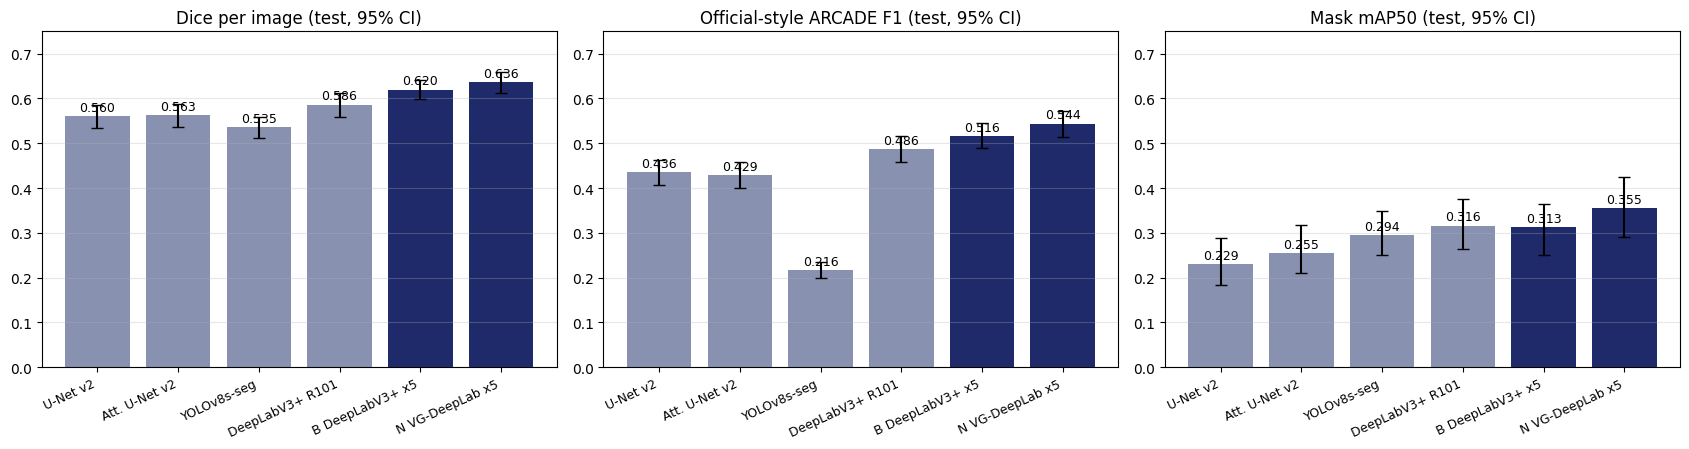

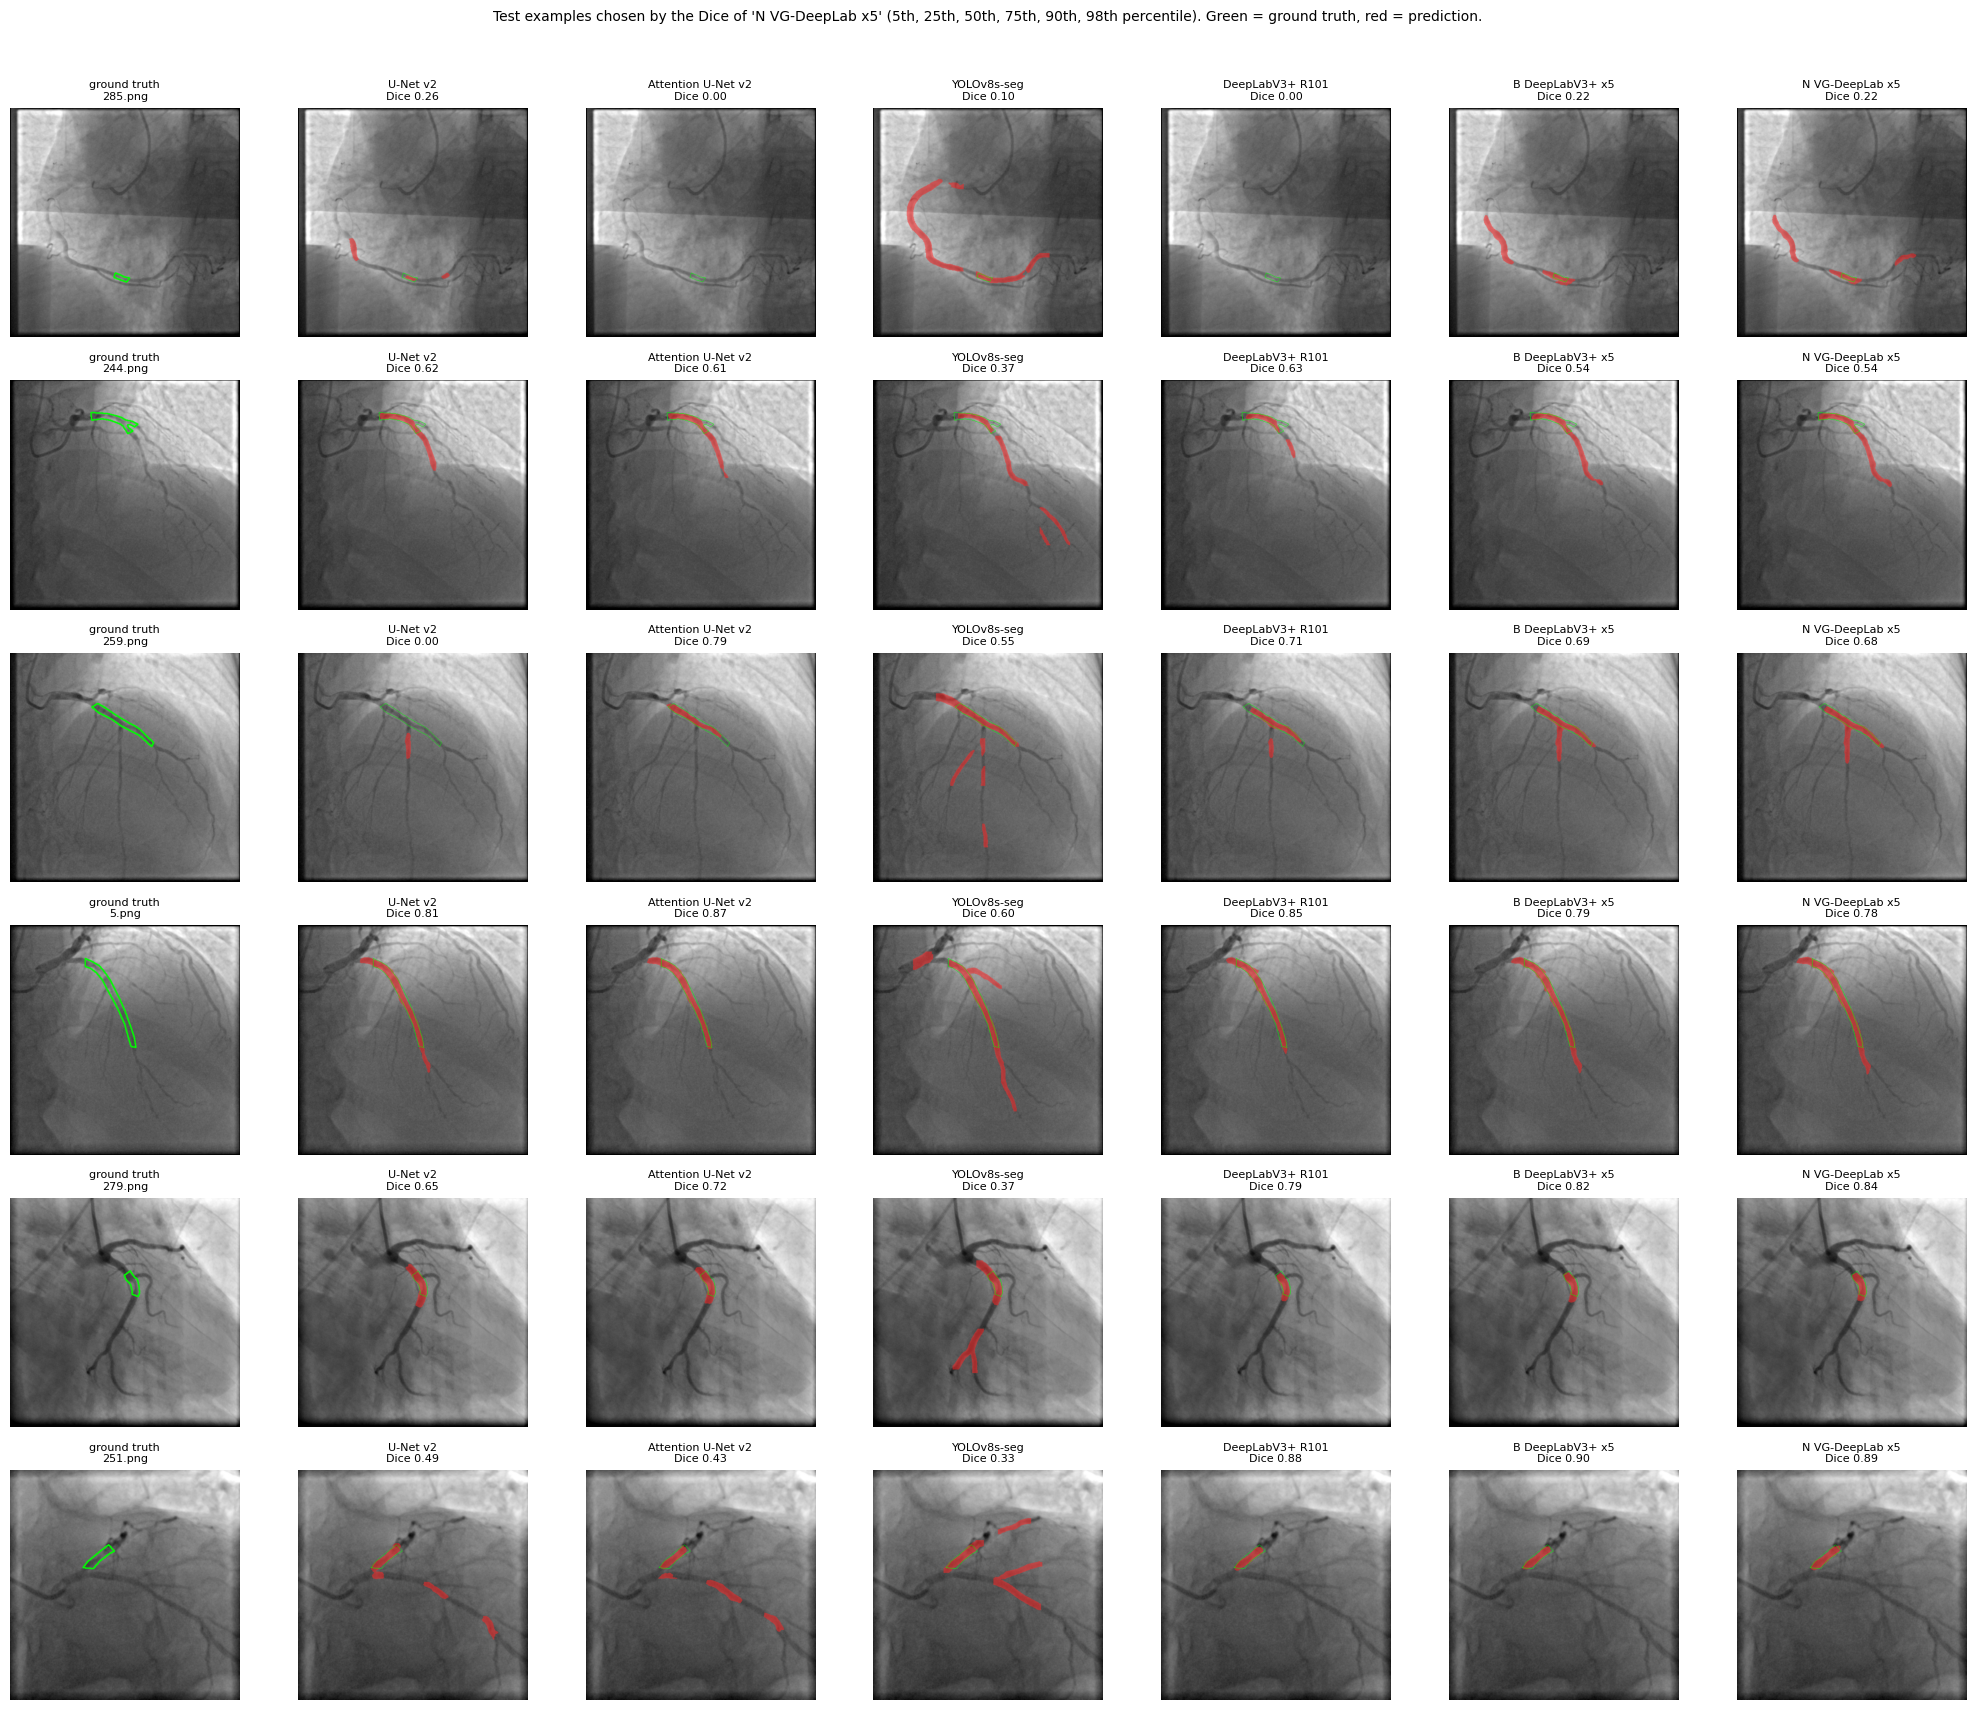

In [11]:
# ============================================================
# Figures for the thesis: bar chart with confidence intervals + qualitative comparison
# ============================================================
try:
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.6)); x = np.arange(len(ORDER)); short = [n.replace("Attention", "Att.") for n in ORDER]
    for a, (title, val, boot) in zip(ax, [("Dice per image", lambda r: r["fm"]["Dice_img"], lambda r: boot_mean(r["fm"]["per_image_Dice"])),
                                          ("Official-style ARCADE F1", lambda r: r["fm"]["P1"], lambda r: boot_mean(r["fm"]["per_image_P1"])),
                                          ("Mask mAP50", lambda r: r["map50"], lambda r: r["map_boot"][:, 0])]):
        v = np.array([val(RES[n]) for n in ORDER]); ci = np.array([ci95(boot(RES[n])) for n in ORDER])
        a.bar(x, v, color=["#8892b0" if "x5" not in n else "#1f2a6b" for n in ORDER], yerr=[np.maximum(v - ci[:, 0], 0), np.maximum(ci[:, 1] - v, 0)], capsize=4)
        for xi, vi in zip(x, v): a.text(xi, vi + 0.012, f"{vi:.3f}", ha="center", fontsize=9)
        a.set_xticks(x); a.set_xticklabels(short, rotation=25, ha="right", fontsize=9); a.set_title(f"{title} (test, 95% CI)"); a.set_ylim(0, max(0.75, float(ci.max()) + 0.08)); a.grid(axis="y", alpha=0.3)
    plt.tight_layout(); plt.savefig(OUT_DIR / "fig_unified_bars.png", dpi=200); plt.show()

    ref = ORDER[-1]; dref = RES[ref]["fm"]["per_image_Dice"]; srt = np.argsort(dref)
    pick = [int(srt[int(q * (N_TEST - 1))]) for q in (0.05, 0.25, 0.5, 0.75, 0.9, 0.98)]
    fig, ax = plt.subplots(len(pick), len(ORDER) + 1, figsize=(2.9 * (len(ORDER) + 1), 2.9 * len(pick)))
    for row, k in enumerate(pick):
        g = cv2.cvtColor(TEST_IMGS[k], cv2.COLOR_GRAY2RGB); gt = paint(TEST_ITEMS[k]["gts"], TEST_ITEMS[k]["shape"]).astype(np.uint8)
        cs, _ = cv2.findContours(gt, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        o = g.copy(); cv2.drawContours(o, cs, -1, (0, 255, 0), 2); ax[row, 0].imshow(o); ax[row, 0].set_title(f"ground truth\n{TEST_ITEMS[k]['file']}", fontsize=8)
        for col, n in enumerate(ORDER, 1):
            pm = paint(RES[n]["preds"][k], TEST_ITEMS[k]["shape"]); o = g.copy(); o[pm] = (0.45 * o[pm] + 0.55 * np.array([255, 40, 40])).astype(np.uint8); cv2.drawContours(o, cs, -1, (0, 255, 0), 1)
            ax[row, col].imshow(o); ax[row, col].set_title(f"{n}\nDice {RES[n]['fm']['per_image_Dice'][k]:.2f}", fontsize=8)
        for a in ax[row]: a.axis("off")
    plt.suptitle(f"Test examples chosen by the Dice of '{ref}' (5th, 25th, 50th, 75th, 90th, 98th percentile). Green = ground truth, red = prediction.", fontsize=10)
    plt.tight_layout(rect=[0, 0, 1, 0.965]); plt.savefig(OUT_DIR / "fig_unified_qualitative.png", dpi=170); plt.show()
except Exception as e:
    ERRORS.append(("figures", repr(e))); print("figures FAILED ->", repr(e)); traceback.print_exc()

In [12]:
# ============================================================
# Save everything
# ============================================================
TAB_A.to_csv(OUT_DIR / "U1_main_comparison.csv", index=False); TAB_B.to_csv(OUT_DIR / "U2_instance_box.csv", index=False); TAB_P.to_csv(OUT_DIR / "U3_pixel_confusion.csv", index=False)
TAB_C.to_csv(OUT_DIR / "U4_arcade_maxF1.csv", index=False); TAB_X.to_csv(OUT_DIR / "U5_models_protocol.csv", index=False); TAB_PAIR.to_csv(OUT_DIR / "U6_paired_bootstrap.csv", index=False)
TAB_REPRO.to_csv(OUT_DIR / "U0_reproduction_checks.csv", index=False)
per = pd.DataFrame({"file": [it["file"] for it in TEST_ITEMS], "n_gt": [len(it["gts"]) for it in TEST_ITEMS]})
for n in ORDER:
    per[f"dice | {n}"] = RES[n]["fm"]["per_image_Dice"].round(4); per[f"official_f1 | {n}"] = RES[n]["fm"]["per_image_P1"].round(4); per[f"n_pred | {n}"] = RES[n]["cnt"][0.5][1]
per.to_csv(OUT_DIR / "per_image_test_metrics.csv", index=False)
# binary test predictions at the headline operating point (bit-packed) -> later figures need no GPU
np.savez_compressed(OUT_DIR / "unified_test_predictions.npz", files=np.array([it["file"] for it in TEST_ITEMS]),
                    **{re.sub(r"[^A-Za-z0-9]+", "_", n): np.packbits(np.stack([paint(p, it["shape"]) for p, it in zip(RES[n]["preds"], TEST_ITEMS)]), axis=-1) for n in ORDER})
# rows that could NOT be re-scored (weights lost): keep them visibly separate from the unified table
pd.DataFrame([
    {"model": "YOLOv8s detection (v4 raw)", "status": "weights lost - NOT re-scored", "box F1@IoU.5": "0.329 (Ultralytics, best-F1 confidence) / 0.310 (fixed confidence 0.25)", "box mAP50": 0.254, "note": "earlier protocol, box level, no confidence interval"},
    {"model": "YOLOv8s-seg (first run, 2 GPUs)", "status": "weights lost - NOT re-scored", "box F1@IoU.5": "-", "box mAP50": "-", "note": "same metric code, ARCADE-protocol selection: official-style F1 0.480, Dice/img 0.522, mask mAP50 0.335; the re-run scored here is the second run"},
]).to_csv(OUT_DIR / "U7_not_rescored_earlier_protocol.csv", index=False)
ZIP = str(BASE / ("results_unified_smoke" if SMOKE_TEST else "results_unified")); shutil.make_archive(ZIP, "zip", OUT_DIR)
print("saved:", sorted(p.name for p in OUT_DIR.iterdir())); print("zip:", ZIP + ".zip")
print("\nERRORS:", ERRORS if ERRORS else "none")
print("reproduction checks:", "none run" if not len(TAB_REPRO) else TAB_REPRO.status.value_counts().to_dict())
print("DONE.")

saved: ['U0_reproduction_checks.csv', 'U1_main_comparison.csv', 'U2_instance_box.csv', 'U3_pixel_confusion.csv', 'U4_arcade_maxF1.csv', 'U5_models_protocol.csv', 'U6_paired_bootstrap.csv', 'U7_not_rescored_earlier_protocol.csv', 'fig_unified_bars.png', 'fig_unified_qualitative.png', 'per_image_test_metrics.csv', 'unified_operating_points.json', 'unified_test_predictions.npz']
zip: /kaggle/working/results_unified.zip

ERRORS: none
reproduction checks: {'OK': 11, 'MISMATCH': 1}
DONE.
